# Frequência escolar acima da exigida — 6 a 17 anos

Análise descritiva do indicador **`sicon_perc_acomp_freq_acima_6_17_anos_apartir_2023_d`**, com foco em comparações entre Unidades da Federação e grandes regiões.

## Metodologia

- Unidade original: município por período de referência (`anomes`).
- Indicador: percentual dos beneficiários acompanhados de 6 a 17 anos com frequência escolar igual ou superior a 75%.
- Consolidação territorial: **razão de somas**, calculada como $100 \times \frac{\sum \text{acima da exigida}}{\sum \text{acompanhados}}$.
- A média simples dos percentuais municipais aparece apenas como medida descritiva. Ela não é usada no indicador consolidado, pois daria o mesmo peso a municípios com populações acompanhadas muito diferentes.
- Fonte local: `cumprimento2025.csv`.

In [1]:
from pathlib import Path
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

BASE_DIR = Path.cwd()
ARQUIVO_DADOS = BASE_DIR / "cumprimento_2024_2026_unificado.csv"

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")

print(f"Python: {sys.version.split()[0]}")
print(f"Executável: {sys.executable}")
print(f"Sistema: {platform.platform()}")
print(f"Diretório de trabalho: {BASE_DIR}")
print(f"CSV encontrado: {ARQUIVO_DADOS.exists()}")
print(f"pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}")

assert ARQUIVO_DADOS.exists(), f"Arquivo não encontrado: {ARQUIVO_DADOS}"

Python: 3.10.12
Executável: /home/gabriel/projetos/outros/teste-bolsa/.venv/bin/python
Sistema: Linux-6.18.35.2-microsoft-standard-WSL2-x86_64-with-glibc2.35
Diretório de trabalho: /home/gabriel/projetos/outros/teste-bolsa
CSV encontrado: True
pandas 2.3.3 | numpy 2.2.6 | seaborn 0.13.2


## 1. Preparação e qualidade dos dados

O código do município permite identificar a UF pelos dois primeiros dígitos. Percentuais ausentes quando o denominador é positivo são reconstruídos pelas quantidades; denominadores nulos permanecem sem percentual.

In [2]:
COL_ACOMPANHADOS = "sicon_qtde_benef_acomp_educacao_6_17_anos_apartir_2023_l"
COL_ACIMA = "sicon_qtde_acomp_freq_acima_6_17_anos_apartir_2023_l"
COL_PERCENTUAL_PUBLICADO = "sicon_perc_acomp_freq_acima_6_17_anos_apartir_2023_d"
COLUNAS = ["codigo_ibge", "anomes", COL_ACOMPANHADOS, COL_ACIMA, COL_PERCENTUAL_PUBLICADO]

UF_POR_PREFIXO = {
    "11": ("RO", "Norte"), "12": ("AC", "Norte"), "13": ("AM", "Norte"),
    "14": ("RR", "Norte"), "15": ("PA", "Norte"), "16": ("AP", "Norte"),
    "17": ("TO", "Norte"), "21": ("MA", "Nordeste"), "22": ("PI", "Nordeste"),
    "23": ("CE", "Nordeste"), "24": ("RN", "Nordeste"), "25": ("PB", "Nordeste"),
    "26": ("PE", "Nordeste"), "27": ("AL", "Nordeste"), "28": ("SE", "Nordeste"),
    "29": ("BA", "Nordeste"), "31": ("MG", "Sudeste"), "32": ("ES", "Sudeste"),
    "33": ("RJ", "Sudeste"), "35": ("SP", "Sudeste"), "41": ("PR", "Sul"),
    "42": ("SC", "Sul"), "43": ("RS", "Sul"), "50": ("MS", "Centro-Oeste"),
    "51": ("MT", "Centro-Oeste"), "52": ("GO", "Centro-Oeste"),
    "53": ("DF", "Centro-Oeste"),
}

territorios = pd.DataFrame.from_dict(
    UF_POR_PREFIXO, orient="index", columns=["uf", "regiao"]
).rename_axis("prefixo_uf").reset_index()

dados = pd.read_csv(ARQUIVO_DADOS, usecols=COLUNAS, dtype={"codigo_ibge": "string"})
dados["prefixo_uf"] = dados["codigo_ibge"].str[:2]
dados = dados.merge(territorios, on="prefixo_uf", how="left", validate="many_to_one")
dados["data_referencia"] = pd.to_datetime(dados["anomes"].astype(str), format="%Y%m")
dados["periodo"] = dados["data_referencia"].dt.strftime("%b/%Y").replace(
    {"Mar/2024": "mar/2024", "May/2024": "mai/2024", "Jul/2024": "jul/2024",
     "Sep/2024": "set/2024", "Nov/2024": "nov/2024",
     "May/2025": "mai/2025", "Jul/2025": "jul/2025",
     "Sep/2025": "set/2025", "Nov/2025": "nov/2025","Mar/2026": "mar/2026",
     "May/2026": "mai/2026"}
)
dados["percentual_calculado"] = np.where(
    dados[COL_ACOMPANHADOS].gt(0),
    100 * dados[COL_ACIMA] / dados[COL_ACOMPANHADOS],
    np.nan,
)
dados["percentual_municipal"] = dados[COL_PERCENTUAL_PUBLICADO].fillna(
    dados["percentual_calculado"]
)

resumo_qualidade = pd.Series({
    "linhas": len(dados),
    "municípios": dados["codigo_ibge"].nunique(),
    "períodos": dados["anomes"].nunique(),
    "UFs": dados["uf"].nunique(),
    "regiões": dados["regiao"].nunique(),
    "duplicidades município-período": dados.duplicated(["codigo_ibge", "anomes"]).sum(),
    "UF não identificada": dados["uf"].isna().sum(),
    "percentuais publicados ausentes": dados[COL_PERCENTUAL_PUBLICADO].isna().sum(),
    "denominadores iguais a zero": dados[COL_ACOMPANHADOS].eq(0).sum(),
    "percentuais municipais utilizáveis": dados["percentual_municipal"].notna().sum(),
    "maior diferença de arredondamento (p.p.)": (
        dados[COL_PERCENTUAL_PUBLICADO] - dados["percentual_calculado"]
    ).abs().max(),
})

display(resumo_qualidade.to_frame("valor"))
assert dados["uf"].nunique() == 27 and dados["regiao"].nunique() == 5
assert dados.duplicated(["codigo_ibge", "anomes"]).sum() == 0
assert dados["uf"].notna().all()
assert (dados[COL_ACIMA] <= dados[COL_ACOMPANHADOS]).all()

,valor
linhas,"66,844.00"
municípios,"5,571.00"
períodos,12.00
UFs,27.00
regiões,5.00
duplicidades município-período,0.00
UF não identificada,0.00
percentuais publicados ausentes,29.00
denominadores iguais a zero,29.00
percentuais municipais utilizáveis,"66,815.00"


## 2. Brasil e estatísticas municipais

A função abaixo aplica a mesma razão de somas a qualquer agrupamento. As medidas de distribuição (`média`, `mediana`, quartis e desvio padrão) descrevem a heterogeneidade entre municípios.

In [3]:
def consolidar(grupo: pd.DataFrame) -> pd.Series:
    acompanhados = grupo[COL_ACOMPANHADOS].sum()
    acima = grupo[COL_ACIMA].sum()
    percentuais = grupo["percentual_municipal"].dropna()
    return pd.Series({
        "beneficiarios_acompanhados": acompanhados,
        "acima_da_exigencia": acima,
        "indicador_pct": 100 * acima / acompanhados if acompanhados else np.nan,
        "media_municipal_pct": percentuais.mean(),
        "mediana_municipal_pct": percentuais.median(),
        "desvio_padrao_pct": percentuais.std(),
        "q1_pct": percentuais.quantile(0.25),
        "q3_pct": percentuais.quantile(0.75),
        "municipios": grupo["codigo_ibge"].nunique(),
    })

brasil_periodo = (
    dados.groupby(["data_referencia", "periodo"], observed=True, sort=True)
    .apply(consolidar, include_groups=False)
    .reset_index()
)

estatisticas_municipais = (
    dados.groupby(["data_referencia", "periodo"], observed=True, sort=True)["percentual_municipal"]
    .describe(percentiles=[0.25, 0.5, 0.75])
    .reset_index()
)

print("Indicador consolidado do Brasil por período")
display(brasil_periodo.round(2))
print("Distribuição dos percentuais municipais por período")
display(estatisticas_municipais.round(2))
assert brasil_periodo["indicador_pct"].between(0, 100).all()

Indicador consolidado do Brasil por período


,data_referencia,periodo,beneficiarios_acompanhados,acima_da_exigencia,indicador_pct,media_municipal_pct,mediana_municipal_pct,desvio_padrao_pct,q1_pct,q3_pct,municipios
0,2024-03-01,mar/2024,"13,358,101.00","12,644,422.00",94.66,95.04,96.54,7.14,93.30,98.66,"5,570.00"
1,2024-05-01,mai/2024,"13,709,887.00","12,821,959.00",93.52,94.31,96.55,10.16,92.71,98.84,"5,570.00"
2,2024-07-01,jul/2024,"14,029,493.00","13,123,886.00",93.54,94.06,96.13,10.24,92.63,98.65,"5,570.00"
3,2024-09-01,set/2024,"14,091,590.00","13,391,346.00",95.03,95.13,96.11,4.48,92.77,98.49,"5,570.00"
4,2024-11-01,nov/2024,"14,049,375.00","13,380,304.00",95.24,95.25,96.57,4.68,92.96,98.81,"5,570.00"
5,2025-03-01,Mar/2025,"13,922,459.00","13,054,952.00",93.77,94.17,95.83,8.12,92.51,98.10,"5,570.00"
6,2025-05-01,mai/2025,"14,107,138.00","13,272,239.00",94.08,94.70,95.80,4.80,92.21,98.34,"5,571.00"
7,2025-07-01,jul/2025,"14,342,139.00","13,548,597.00",94.47,94.51,95.74,5.01,91.95,98.45,"5,570.00"
8,2025-09-01,set/2025,"13,399,518.00","12,703,268.00",94.80,94.91,95.72,4.13,92.54,98.08,"5,570.00"
9,2025-11-01,nov/2025,"13,186,459.00","12,587,533.00",95.46,95.38,96.38,4.15,93.10,98.61,"5,571.00"


Distribuição dos percentuais municipais por período


,data_referencia,periodo,count,mean,std,min,25%,50%,75%,max
0,2024-03-01,mar/2024,"5,570.00",95.04,7.14,0.00,93.30,96.54,98.66,100.00
1,2024-05-01,mai/2024,"5,565.00",94.31,10.16,0.00,92.71,96.55,98.84,100.00
2,2024-07-01,jul/2024,"5,568.00",94.06,10.24,0.00,92.63,96.13,98.65,100.00
3,2024-09-01,set/2024,"5,569.00",95.13,4.48,2.58,92.77,96.11,98.49,100.00
4,2024-11-01,nov/2024,"5,562.00",95.25,4.68,43.83,92.96,96.57,98.81,100.00
5,2025-03-01,Mar/2025,"5,566.00",94.17,8.12,0.00,92.51,95.83,98.10,100.00
6,2025-05-01,mai/2025,"5,570.00",94.70,4.80,15.43,92.21,95.80,98.34,100.00
7,2025-07-01,jul/2025,"5,568.00",94.51,5.01,60.34,91.95,95.74,98.45,100.00
8,2025-09-01,set/2025,"5,567.00",94.91,4.13,51.81,92.54,95.72,98.08,100.00
9,2025-11-01,nov/2025,"5,570.00",95.38,4.15,62.62,93.10,96.38,98.61,100.00


## 3. Comparação entre regiões ao longo de 2025

As curvas mostram o indicador consolidado em cada região. A linha tracejada representa o Brasil.

periodo,mar/2024,mai/2024,jul/2024,set/2024,nov/2024,Mar/2025,mai/2025,jul/2025,set/2025,nov/2025,mar/2026,mai/2026
regiao,,,,,,,,,,,,
Centro-Oeste,96.09,95.39,95.42,95.64,96.04,95.49,94.80,94.88,95.27,95.49,96.43,95.32
Nordeste,96.25,97.13,94.41,97.07,97.51,95.42,95.73,97.02,96.61,97.16,97.70,96.98
Norte,94.33,97.38,96.65,96.72,97.07,93.60,96.68,97.27,96.90,97.48,97.95,97.19
Sudeste,92.76,91.83,92.14,92.13,91.91,91.61,91.15,90.86,91.92,92.78,93.56,92.41
Sul,93.43,74.97,87.84,92.16,92.24,92.59,91.82,89.97,91.80,92.36,93.93,92.32


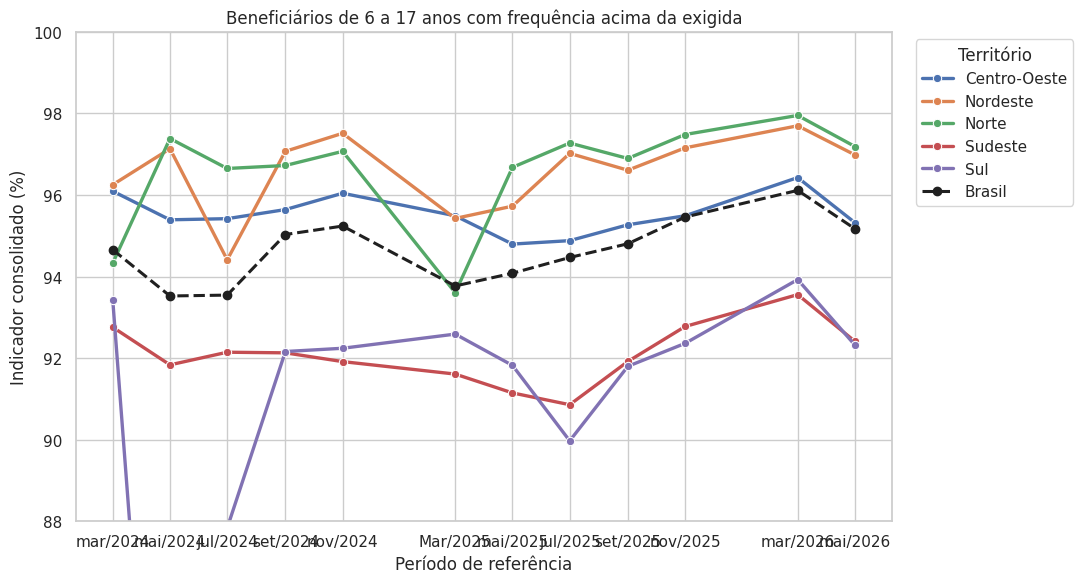

In [4]:
regiao_periodo = (
    dados.groupby(["regiao", "data_referencia", "periodo"], observed=True, sort=True)
    .apply(consolidar, include_groups=False)
    .reset_index()
)
tabela_regioes = regiao_periodo.pivot(
    index="regiao", columns="periodo", values="indicador_pct"
)
tabela_regioes = tabela_regioes[
    brasil_periodo.sort_values("data_referencia")["periodo"].tolist()
]
display(tabela_regioes.round(2))

fig, ax = plt.subplots(figsize=(11, 6))
sns.lineplot(
    data=regiao_periodo, x="data_referencia", y="indicador_pct",
    hue="regiao", marker="o", linewidth=2.4, ax=ax,
)
ax.plot(
    brasil_periodo["data_referencia"], brasil_periodo["indicador_pct"],
    color="#202020", linestyle="--", marker="o", linewidth=2.2, label="Brasil",
)
ax.set_title("Beneficiários de 6 a 17 anos com frequência acima da exigida")
ax.set_xlabel("Período de referência")
ax.set_ylabel("Indicador consolidado (%)")
ax.set_xticks(brasil_periodo["data_referencia"], brasil_periodo["periodo"])
ax.set_ylim(88, 100)
ax.legend(title="Território", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

assert regiao_periodo.groupby("data_referencia")["regiao"].nunique().eq(5).all()

## 4. Comparação entre UFs

O ranking usa o período mais recente disponível. A tabela combina o indicador consolidado, baseado nas quantidades, com medidas da distribuição municipal. O mapa de calor preserva a comparação ao longo dos cinco períodos.

Ranking das UFs — mai/2026


,uf,regiao,beneficiarios_acompanhados,acima_da_exigencia,indicador_pct,media_municipal_pct,mediana_municipal_pct,desvio_padrao_pct,q1_pct,q3_pct,municipios
1,DF,Centro-Oeste,"132,827.00","131,037.00",98.65,98.65,98.65,NaN,98.65,98.65,1.00
2,MA,Nordeste,"805,025.00","793,415.00",98.56,98.65,99.14,1.54,98.12,99.77,217.00
3,PA,Norte,"980,012.00","958,483.00",97.80,97.99,98.32,1.84,97.22,99.31,144.00
4,PB,Nordeste,"367,156.00","358,701.00",97.70,97.41,98.21,2.87,96.44,99.52,223.00
5,BA,Nordeste,"1,382,554.00","1,345,382.00",97.31,97.52,98.05,2.21,96.29,99.17,417.00
6,AL,Nordeste,"318,579.00","309,885.00",97.27,98.04,98.47,2.27,97.23,99.74,102.00
7,AC,Norte,"101,961.00","98,875.00",96.97,97.27,98.18,2.81,95.99,99.04,22.00
8,PE,Nordeste,"939,523.00","910,679.00",96.93,97.33,97.45,1.74,96.38,98.54,185.00
9,PI,Nordeste,"350,949.00","339,917.00",96.86,98.15,99.04,2.72,97.32,100.00,224.00
10,AM,Norte,"515,753.00","499,101.00",96.77,97.96,98.35,1.62,96.72,99.38,62.00


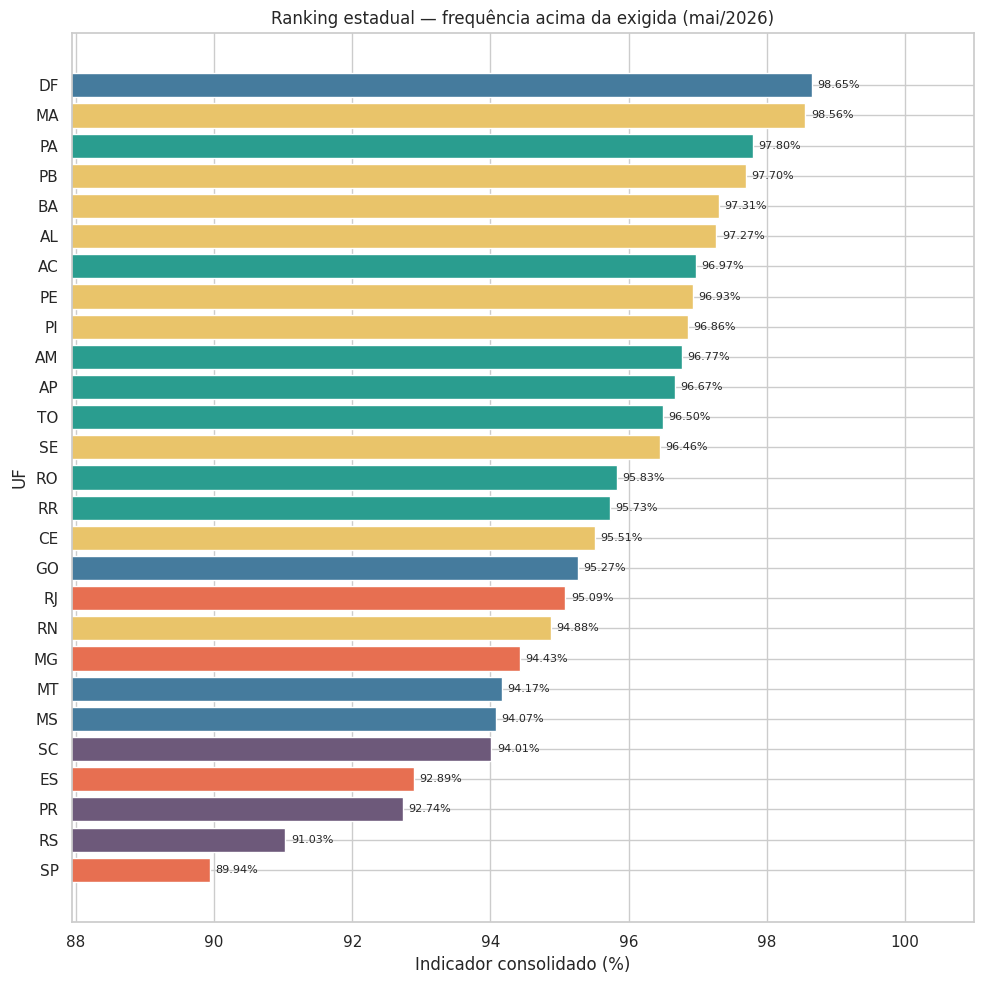

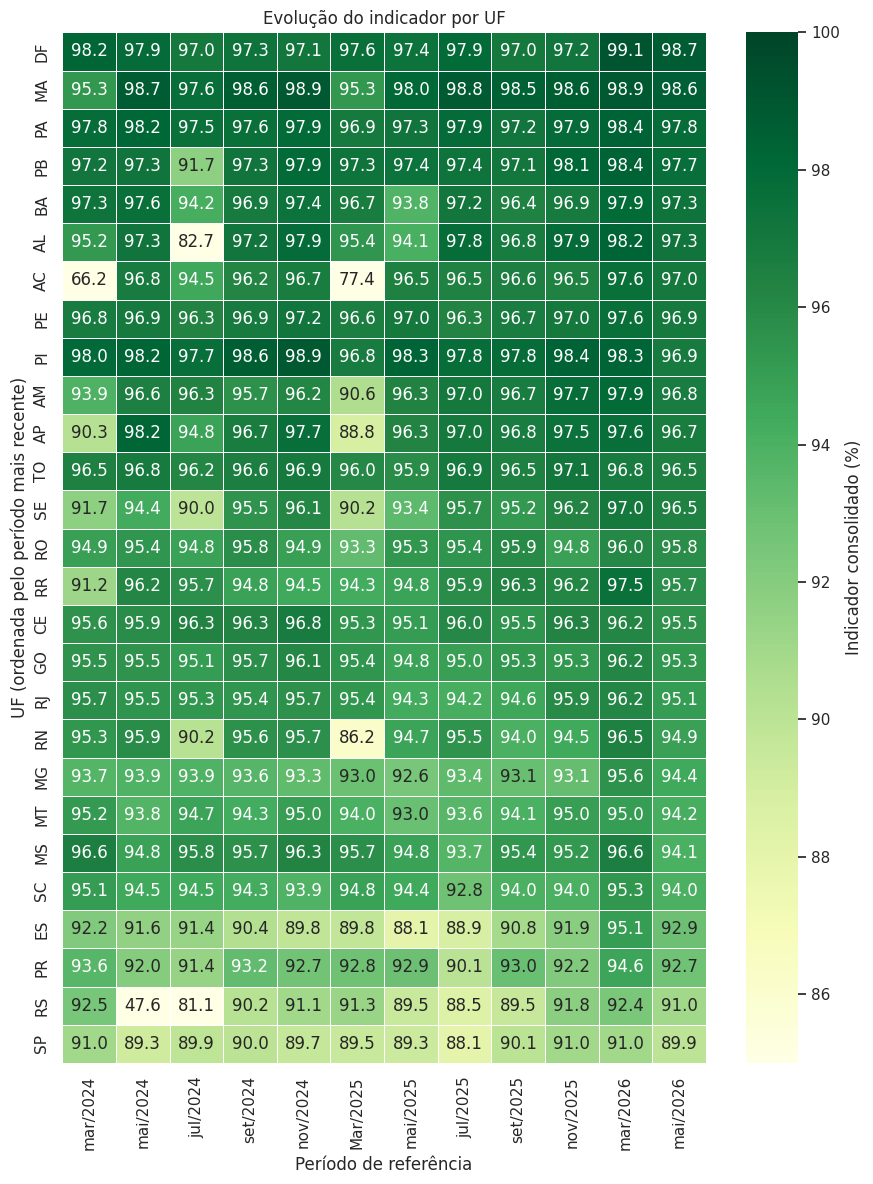

In [6]:
uf_periodo = (
    dados.groupby(["uf", "regiao", "data_referencia", "periodo"], observed=True, sort=True)
    .apply(consolidar, include_groups=False)
    .reset_index()
)
data_mais_recente = dados["data_referencia"].max()
rotulo_mais_recente = dados.loc[
    dados["data_referencia"].eq(data_mais_recente), "periodo"
].iloc[0]

ranking_uf = (
    uf_periodo.loc[uf_periodo["data_referencia"].eq(data_mais_recente)]
    .sort_values("indicador_pct", ascending=False)
    .reset_index(drop=True)
)
ranking_uf.index = ranking_uf.index + 1
colunas_ranking = [
    "uf", "regiao", "beneficiarios_acompanhados", "acima_da_exigencia",
    "indicador_pct", "media_municipal_pct", "mediana_municipal_pct",
    "desvio_padrao_pct", "q1_pct", "q3_pct", "municipios",
]
print(f"Ranking das UFs — {rotulo_mais_recente}")
display(ranking_uf[colunas_ranking].round(2))

fig, ax = plt.subplots(figsize=(10, 10))
cores_regiao = {
    "Norte": "#2a9d8f", "Nordeste": "#e9c46a", "Centro-Oeste": "#457b9d",
    "Sudeste": "#e76f51", "Sul": "#6d597a",
}
ordem_ranking = ranking_uf.sort_values("indicador_pct", ascending=True)
ax.barh(
    ordem_ranking["uf"], ordem_ranking["indicador_pct"],
    color=ordem_ranking["regiao"].map(cores_regiao),
)
for posicao, valor in enumerate(ordem_ranking["indicador_pct"]):
    ax.text(valor + 0.08, posicao, f"{valor:.2f}%", va="center", fontsize=8)
ax.set_title(f"Ranking estadual — frequência acima da exigida ({rotulo_mais_recente})")
ax.set_xlabel("Indicador consolidado (%)")
ax.set_ylabel("UF")
ax.set_xlim(max(0, ordem_ranking["indicador_pct"].min() - 2), 101)
plt.tight_layout()
plt.show()

heatmap_uf = uf_periodo.pivot(index="uf", columns="periodo", values="indicador_pct")
heatmap_uf = heatmap_uf[brasil_periodo.sort_values("data_referencia")["periodo"].tolist()]
heatmap_uf = heatmap_uf.loc[ranking_uf["uf"]]
fig, ax = plt.subplots(figsize=(9, 12))
sns.heatmap(
    heatmap_uf, annot=True, fmt=".1f", cmap="YlGn", vmin=85, vmax=100,
    linewidths=0.4, cbar_kws={"label": "Indicador consolidado (%)"}, ax=ax,
)
ax.set_title("Evolução do indicador por UF")
ax.set_xlabel("Período de referência")
ax.set_ylabel("UF (ordenada pelo período mais recente)")
plt.tight_layout()
plt.show()



## 5. Dispersão municipal e desigualdade dentro das regiões

O boxplot resume a distribuição dos percentuais municipais no período mais recente. A amplitude regional mede, em pontos percentuais, a distância entre a UF com maior e menor indicador consolidado dentro de cada região.

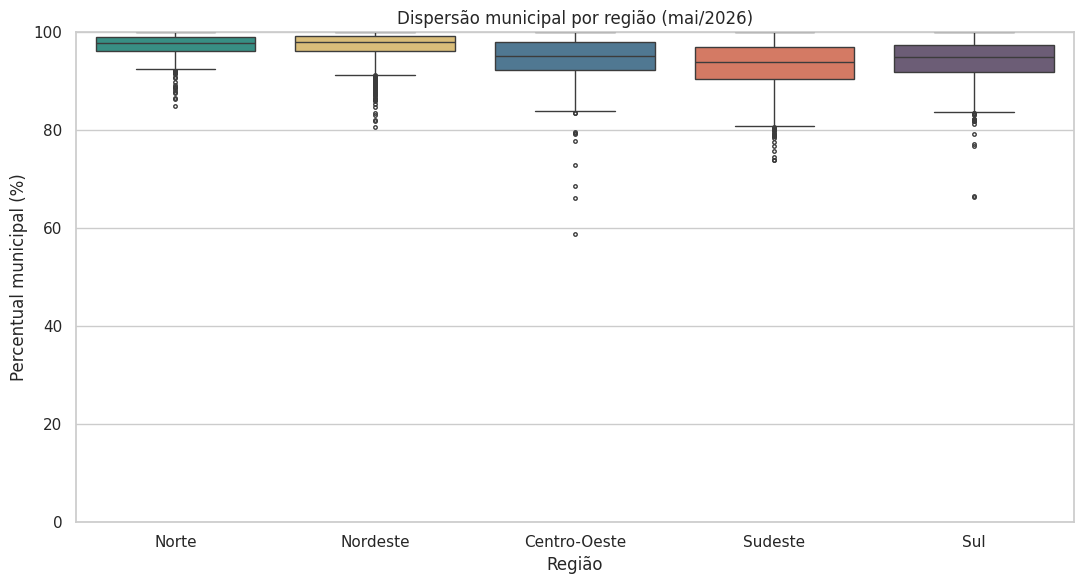

Amplitude entre UFs dentro de cada região — mai/2026


,regiao,melhor_uf,melhor_indicador_pct,pior_uf,pior_indicador_pct,amplitude_pp
0,Sudeste,RJ,95.09,SP,89.94,5.15
1,Centro-Oeste,DF,98.65,MS,94.07,4.58
2,Nordeste,MA,98.56,RN,94.88,3.68
3,Sul,SC,94.01,RS,91.03,2.98
4,Norte,PA,97.80,RR,95.73,2.07


In [7]:
dados_recentes = dados.loc[dados["data_referencia"].eq(data_mais_recente)].copy()
ordem_regioes = (
    regiao_periodo.loc[regiao_periodo["data_referencia"].eq(data_mais_recente)]
    .sort_values("indicador_pct", ascending=False)["regiao"]
    .tolist()
)

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(
    data=dados_recentes, x="regiao", y="percentual_municipal",
    order=ordem_regioes, hue="regiao", palette=cores_regiao,
    legend=False, showfliers=True, fliersize=2.5, ax=ax,
)
ax.set_title(f"Dispersão municipal por região ({rotulo_mais_recente})")
ax.set_xlabel("Região")
ax.set_ylabel("Percentual municipal (%)")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

registros_amplitude = []
for regiao, grupo in ranking_uf.groupby("regiao", sort=False):
    melhor = grupo.loc[grupo["indicador_pct"].idxmax()]
    pior = grupo.loc[grupo["indicador_pct"].idxmin()]
    registros_amplitude.append({
        "regiao": regiao,
        "melhor_uf": melhor["uf"],
        "melhor_indicador_pct": melhor["indicador_pct"],
        "pior_uf": pior["uf"],
        "pior_indicador_pct": pior["indicador_pct"],
        "amplitude_pp": melhor["indicador_pct"] - pior["indicador_pct"],
    })
amplitude_regional = pd.DataFrame(registros_amplitude).sort_values(
    "amplitude_pp", ascending=False
).reset_index(drop=True)
print(f"Amplitude entre UFs dentro de cada região — {rotulo_mais_recente}")
display(amplitude_regional.round(2))
assert amplitude_regional["amplitude_pp"].ge(0).all()

## 6. Síntese automática

As conclusões abaixo são calculadas a partir das tabelas anteriores, portanto se atualizam quando o CSV é substituído por uma nova versão com a mesma estrutura.

In [9]:
regioes_recentes = regiao_periodo.loc[
    regiao_periodo["data_referencia"].eq(data_mais_recente)
].sort_values("indicador_pct", ascending=False)
melhor_regiao = regioes_recentes.iloc[0]
pior_regiao = regioes_recentes.iloc[-1]
melhor_uf = ranking_uf.iloc[0]
pior_uf = ranking_uf.iloc[-1]
amplitude_nacional = melhor_uf["indicador_pct"] - pior_uf["indicador_pct"]
primeiro_brasil = brasil_periodo.sort_values("data_referencia").iloc[0]
ultimo_brasil = brasil_periodo.sort_values("data_referencia").iloc[-1]
variacao_brasil = ultimo_brasil["indicador_pct"] - primeiro_brasil["indicador_pct"]

sinal = "aumento" if variacao_brasil >= 0 else "redução"
print("SÍNTESE DOS RESULTADOS")
print(f"• Melhor região em {rotulo_mais_recente}: {melhor_regiao['regiao']} ({melhor_regiao['indicador_pct']:.2f}%).")
print(f"• Região com menor resultado: {pior_regiao['regiao']} ({pior_regiao['indicador_pct']:.2f}%).")
print(f"• Melhor UF: {melhor_uf['uf']} ({melhor_uf['indicador_pct']:.2f}%).")
print(f"• UF com menor resultado: {pior_uf['uf']} ({pior_uf['indicador_pct']:.2f}%).")
print(f"• Amplitude nacional entre UFs: {amplitude_nacional:.2f} pontos percentuais.")
print(
    f"• Brasil: {primeiro_brasil['indicador_pct']:.2f}% em {primeiro_brasil['periodo']} e "
    f"{ultimo_brasil['indicador_pct']:.2f}% em {ultimo_brasil['periodo']}, "
    f"{sinal} de {abs(variacao_brasil):.2f} pontos percentuais."
)

assert amplitude_nacional >= 0
assert np.isfinite(variacao_brasil)

SÍNTESE DOS RESULTADOS
• Melhor região em nov/2025: Norte (97.48%).
• Região com menor resultado: Sul (92.36%).
• Melhor UF: MA (98.63%).
• UF com menor resultado: SP (91.04%).
• Amplitude nacional entre UFs: 7.60 pontos percentuais.
• Brasil: 93.77% em mar/2025 e 95.46% em nov/2025, aumento de 1.69 pontos percentuais.
